In [1]:
import numpy as np
import mitsuba as mi
from typing import cast

from sionna.rt import (load_scene, Transmitter, Receiver, PlanarArray,
                       RadioMapSolver, PathSolver, Camera, cpx_abs_square,
                       PlanarRadioMap)

import matplotlib.pyplot as plt

CELL_SIZE = 2.5
SAMPLES = 10**7

jitc_llvm_init(): LLVM API initialization failed ..


In [2]:
scene = load_scene("Cinema1.xml")

In [3]:
for i,obj in enumerate(scene.objects.values()):
    print(f"{obj.name} : {obj.radio_material.name}")
    if i == 10:
        break

plane : itu_concrete
no-name-1 : itu_metal
map_osm_buildings-itu_marble : itu_marble


In [4]:
scene.tx_array = PlanarArray(num_rows=4,
                             num_cols=4,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="iso",
                             polarization = "V")

scene.rx_array = PlanarArray(num_rows=1,
                             num_cols=1,
                             vertical_spacing=0.5,
                             horizontal_spacing=0.5,
                             pattern="iso",
                             polarization = "V")

scene.remove("tx")
scene.remove("rx")

tx = Transmitter("tx", [-85.15, 1.721, 60.0], [0.0, 0.0, 0.0],power_dbm=44)
scene.add(tx)

rx = Receiver("rx", [140.0, 220.0, 1.5], [0.0, 0.0, 0.0])
scene.add(rx)

In [5]:
from typing import cast
from sionna.rt import PlanarRadioMap

cm = cast(
    PlanarRadioMap,
    RadioMapSolver()(scene,
                     cell_size=mi.Point2f(CELL_SIZE, CELL_SIZE),
                     samples_per_tx=SAMPLES),
)

In [6]:
scene.radio_materials["itu_concrete"].color = (0.08, 0.08, 0.10)

scene._preview_widget = None

scene.preview(radio_map=cm)

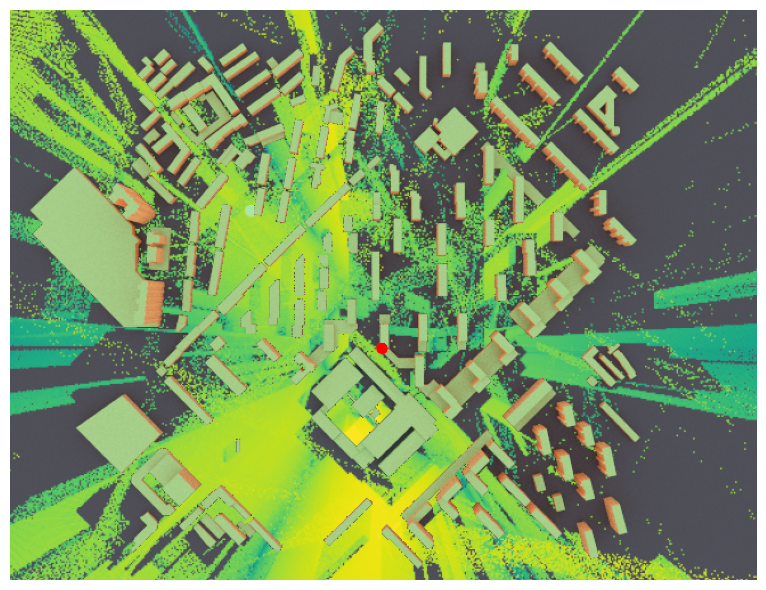

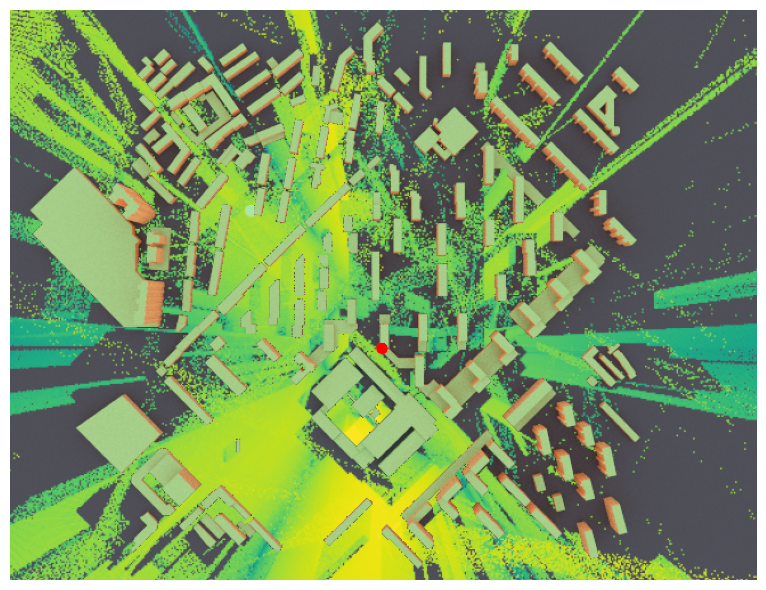

In [7]:
cam = Camera(position=[0, 0, 1500], look_at=[0, 0, 0])
scene.render(camera=cam, radio_map=cm)

In [8]:
path = PathSolver()(scene, max_depth=3, samples_per_src=10**6)
print("num paths:", path.tau.shape[-1])

num paths: 10


In [9]:
scene.preview(paths=path)

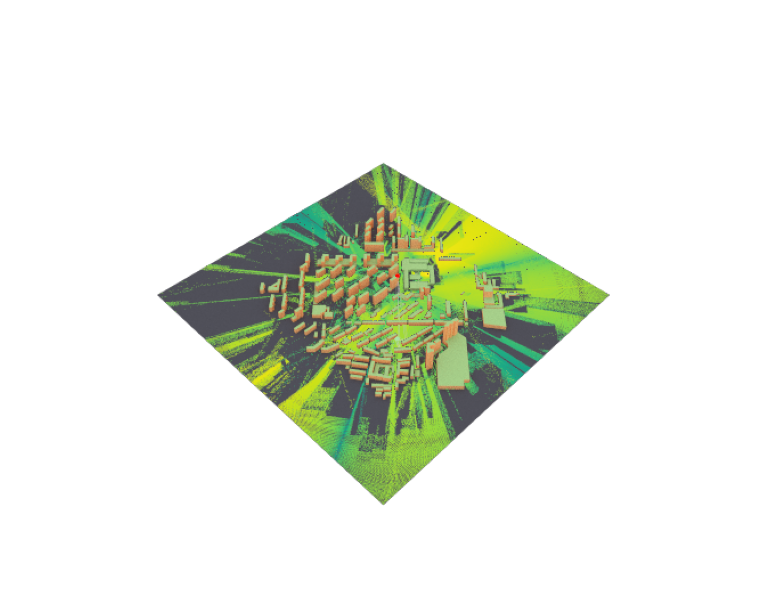

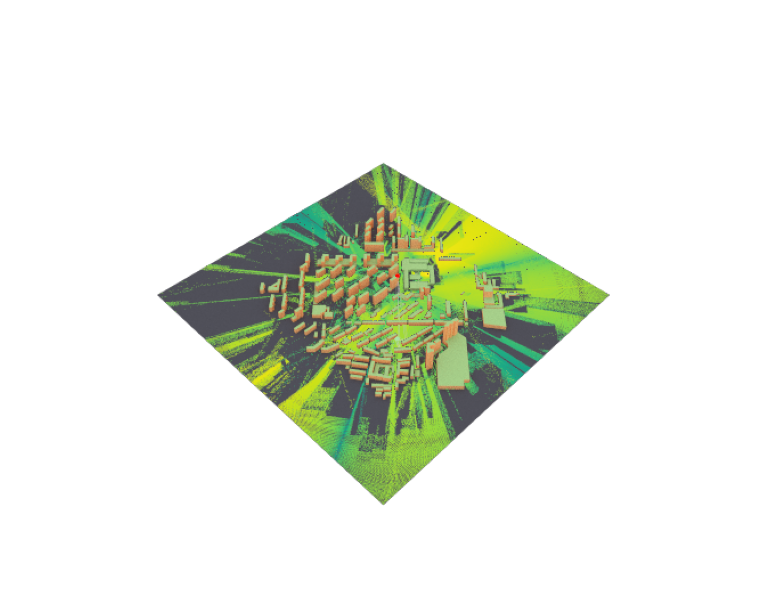

In [10]:
scene.render(camera="preview", paths=path, radio_map=cm)

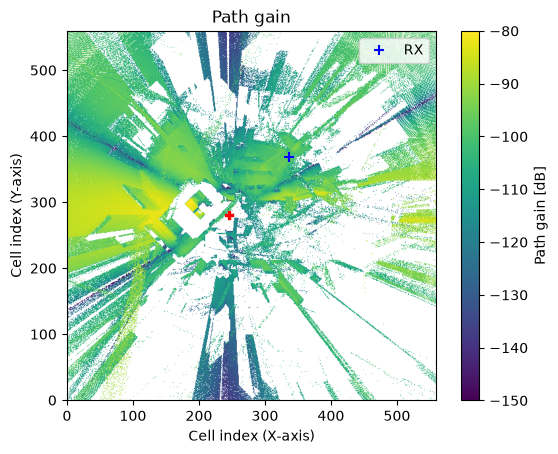

In [11]:
fig = cm.show(metric="path_gain", vmin=-150, vmax=-80)

ax = fig.axes[0]

if cm.num_rx > 0:
    ids = cm.rx_cell_indices          # convert the index into the coordinate of the cell
    rx_x = ids.x.numpy()
    rx_y = ids.y.numpy()

    ax.plot(rx_x, rx_y,
            marker="+", linestyle="", color="blue",
            markersize=7, markeredgewidth=1.5, label="RX")

    ax.legend()
else:
    print("No Receiver!")

In [12]:
from sionna.rt import cpx_abs_square

a, tau = path.cir(
    sampling_frequency=fs,
    num_time_steps=1,
    normalize_delays=False,
    out_type="numpy",
)

tx_index = 0
rx_index = 0

a_abs_square = cpx_abs_square(path.a).numpy()

a_abs_square = np.sum(a_abs_square, axis=3)

a_abs_square = np.squeeze(a_abs_square, axis=1)

a_abs_square = a_abs_square[rx_index, tx_index, :]
tau_ns = path.tau.numpy()[rx_index, tx_index, :] * 1e9

valid = path.valid.numpy()[rx_index, tx_index, :]
a_abs_square = a_abs_square[valid]
tau_ns = tau_ns[valid]

plt.figure()
plt.stem(tau_ns, a_abs_square)
plt.xlabel("Delay [ns]")
plt.ylabel("Path gain (|a|²)")
plt.title("Channel impulse response")
plt.grid(True)
plt.show()

NameError: name 'fs' is not defined

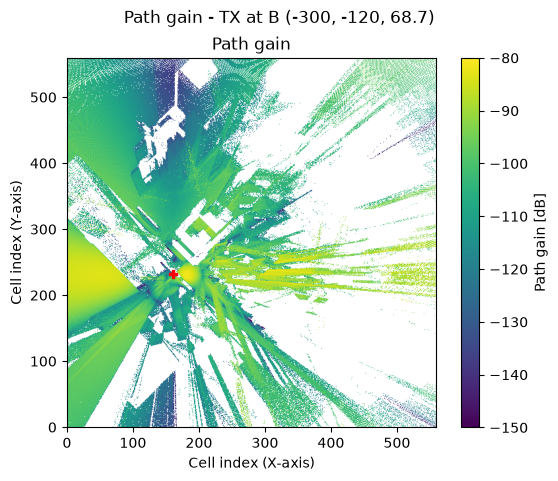

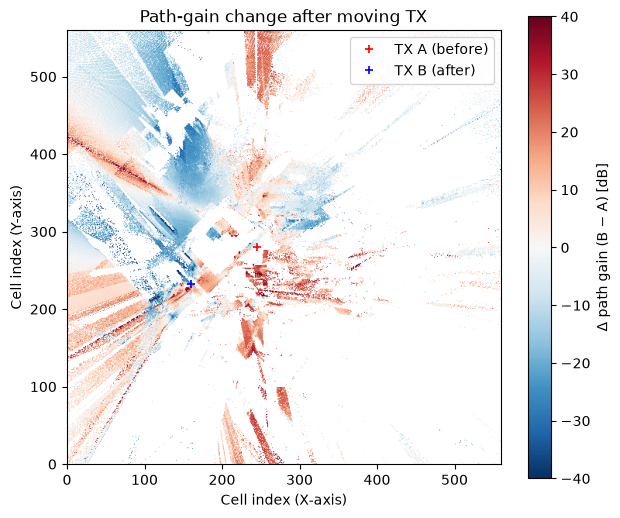

In [ ]:
from typing import cast
from sionna.rt import PlanarRadioMap

POS_A = (-85.15, 1.721, 60.0)

POS_B = (-300.0, -120.0, 68.7)

tx.position = mi.Point3f(*POS_A)
cm_a = cast(
    PlanarRadioMap,
    RadioMapSolver()(scene,
                     cell_size=mi.Point2f(CELL_SIZE, CELL_SIZE),
                     samples_per_tx=SAMPLES),
)
pg_a = cm_a.path_gain.numpy()[0]

tx.position = mi.Point3f(*POS_B)
cm_b = cast(
    PlanarRadioMap,
    RadioMapSolver()(scene,
                     cell_size=mi.Point2f(CELL_SIZE, CELL_SIZE),
                     samples_per_tx=SAMPLES),
)
pg_b = cm_b.path_gain.numpy()[0]

fig = cm_b.show(metric="path_gain", vmin=-150, vmax=-80)
fig.suptitle("Path gain - TX at B (-300, -120, 68.7)")

def To_db(p):
    out = np.full(p.shape, np.nan)
    valid = p > 0
    out[valid] = 10 * np.log10(p[valid])
    return out

delta = To_db(pg_b) - To_db(pg_a)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(delta, origin="lower", cmap="RdBu_r", vmin=-40, vmax=40)
fig.colorbar(im, ax=ax, label="Δ path gain (B − A) [dB]")

a_ids = cm_a.tx_cell_indices
b_ids = cm_b.tx_cell_indices
ax.plot(a_ids.x.numpy(), a_ids.y.numpy(),
        marker="+", linestyle="", color="red",
        markersize=6, markeredgewidth=1.2, label="TX A (before)")
ax.plot(b_ids.x.numpy(), b_ids.y.numpy(),
        marker="+", linestyle="", color="blue",
        markersize=6, markeredgewidth=1.2, label="TX B (after)")
ax.legend(loc="upper right")

ax.set_xlabel("Cell index (X-axis)")
ax.set_ylabel("Cell index (Y-axis)")
ax.set_title("Path-gain change after moving TX")
plt.show()

In [ ]:
scene._preview_widget = None

scene.preview(radio_map=cm_b)

In [ ]:
path2 = PathSolver()(scene, max_depth=5, samples_per_src=10**6)
print("num paths:", path2.tau.shape[-1])   # depth=5 时 B 位置实测 11 条

scene.preview(paths=path2, radio_map=cm_b)

num paths: 11


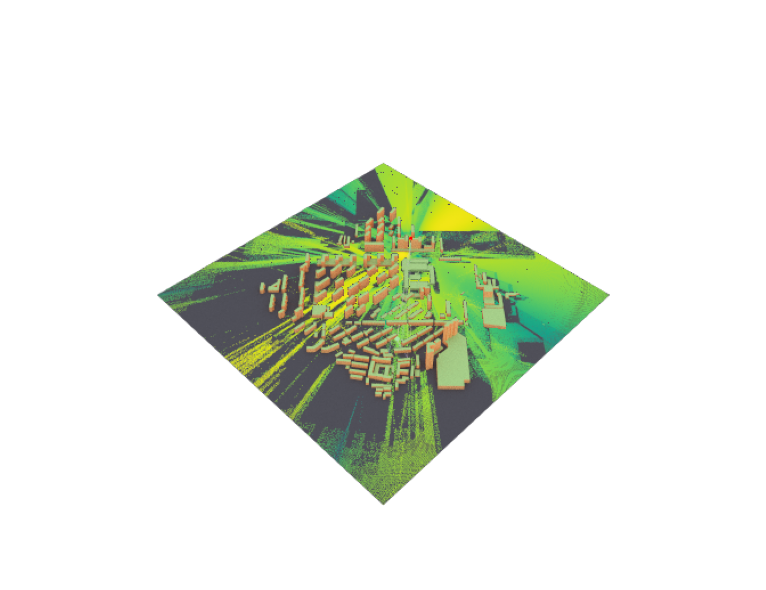

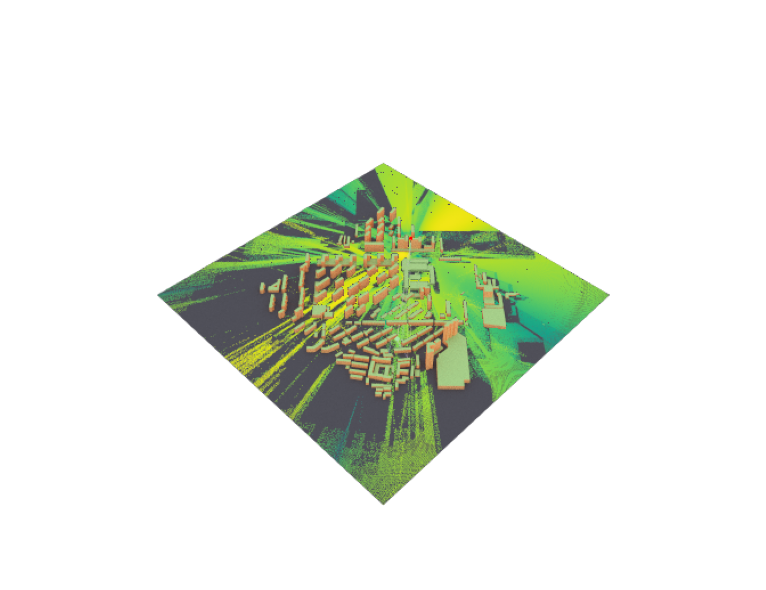

In [ ]:
scene.render(camera="preview",paths=path2,radio_map=cm_b)